# Understanding a Pretrained Vision Transformer

This notebook follows an image through **ViT-Base/16**, using its pretrained weights to examine patch projection, token embeddings, self-attention, and ImageNet classification. We also check selected calculations against the model's own outputs.

<p align="center"><img src="assets/model_scheme.jpg" width="650"></p>
<p align="center"><em>Figure 1. Vision Transformer architecture: patch and positional embeddings, the classification token, and the Transformer encoder. Architecture based on Dosovitskiy et al. (2021).</em></p>

The sections follow the path in Figure 1, from the image patches at the bottom left to the classification head at the top. The encoder diagram on the right shows the operations repeated in each block.

Use `image_path` in Section 2 to choose an image. Install dependencies with `python -m pip install torch transformers pillow matplotlib numpy`. The pretrained weights download on first use. Run the cells in order.

**Reference:** [Dosovitskiy et al., *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale* (ICLR 2021)](https://arxiv.org/abs/2010.11929).

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from matplotlib.patches import Rectangle, ConnectionPatch
from transformers import ViTForImageClassification, ViTImageProcessor

## 1. Load ViT-Base/16

The original ViT architecture begins with non-overlapping image patches and a learned linear projection. Here we use a pretrained **ViT-Base/16** classifier: 16 × 16 patches, 768 features per token, 12 encoder blocks, and 12 attention heads per block.

In [14]:
model_name = "google/vit-base-patch16-224"
processor = ViTImageProcessor.from_pretrained(model_name)
model = ViTForImageClassification.from_pretrained(model_name, attn_implementation="eager")
model.eval()

config = model.config
patch_size = config.patch_size
num_heads = config.num_attention_heads
head_dim = config.hidden_size // num_heads
print(f"Patch size: {patch_size} × {patch_size}")
print(f"Embedding size: {config.hidden_size}")
print(f"Transformer blocks: {config.num_hidden_layers}")
print(f"Attention heads: {num_heads}, features per head: {head_dim}")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Patch size: 16 × 16
Embedding size: 768
Transformer blocks: 12
Attention heads: 12, features per head: 64


## 2. Image input and patch grid

The model's image processor resizes, crops, and normalizes the chosen image. The model receives **1 × 3 × 224 × 224** values, divided into **14 × 14 = 196** patches. The grid is drawn on the processed image, not the original photograph.

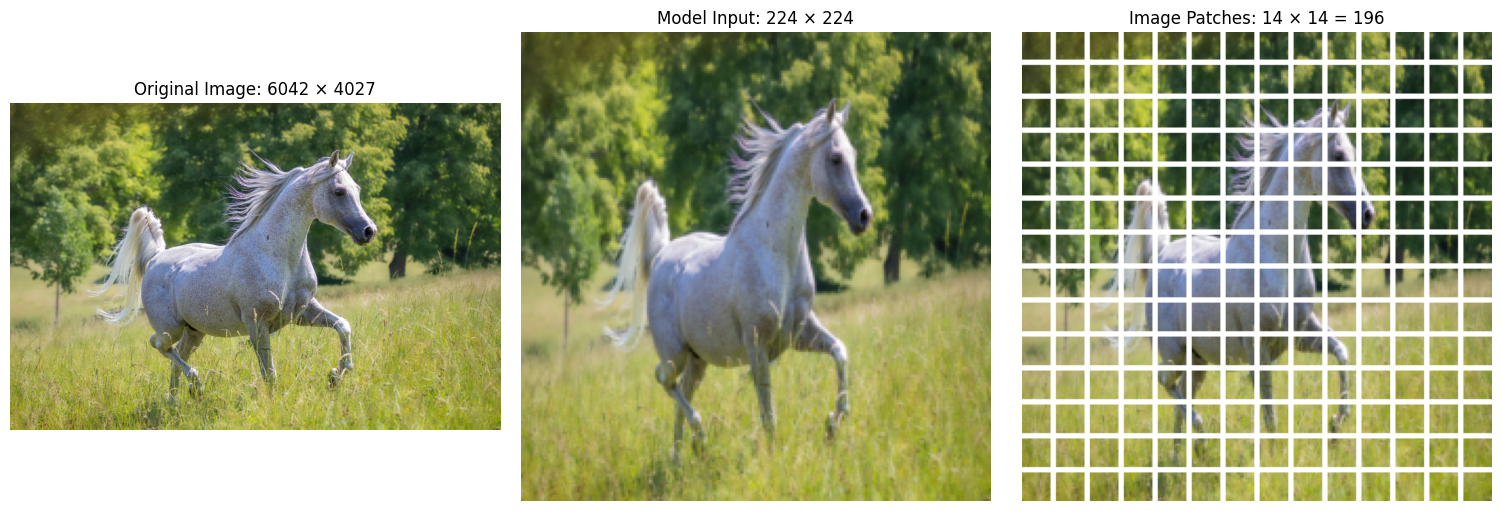

Input tensor: (1, 3, 224, 224)
Total patches: 196


In [ ]:

image_path = "images/horse.jpg"
image = Image.open(image_path).convert("RGB")
pixel_values = processor(images=image, return_tensors="pt")["pixel_values"]

mean = torch.tensor(processor.image_mean)
std = torch.tensor(processor.image_std)
processed = (pixel_values[0].permute(1, 2, 0) * std + mean).clamp(0, 1).numpy()

height, width = processed.shape[:2]
rows, cols = height // patch_size, width // patch_size

gap = 3
patch_view = np.ones((height + (rows - 1) * gap, width + (cols - 1) * gap, 3))

for row in range(rows):
    for col in range(cols):
        y, x = row * patch_size, col * patch_size
        yy, xx = row * (patch_size + gap), col * (patch_size + gap)
        patch_view[yy:yy + patch_size, xx:xx + patch_size] = processed[
            y:y + patch_size, x:x + patch_size
        ]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

axes[0].imshow(image)
axes[0].set_title(f"Original Image: {image.width} × {image.height}")

axes[1].imshow(processed)
axes[1].set_title(f"Model Input: {width} × {height}")

axes[2].imshow(patch_view)
axes[2].set_title(f"Image Patches: {rows} × {cols} = {rows * cols}")

for ax in axes:
    ax.axis("off")

plt.show()

print("Input tensor:", tuple(pixel_values.shape))
print("Total patches:", rows * cols)


## 3. Select and enlarge a patch

Each 16 × 16 RGB patch contains **768 pixel values**. Select a row and column below; the blue outline and enlarged view show the corresponding region. The model receives this patch in **channel-first** order (3 × 16 × 16).

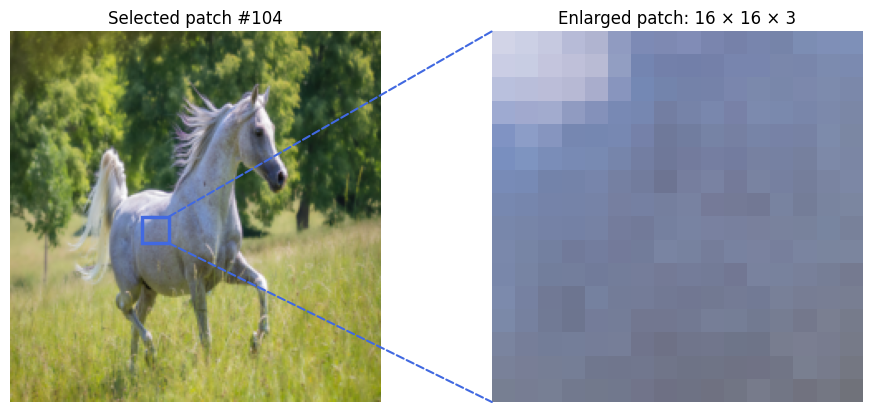

Selected patch tensor: (3, 16, 16)


In [ ]:
patch_row, patch_col = 7, 5
patch_index = patch_row * cols + patch_col
x0, y0 = patch_col * patch_size, patch_row * patch_size
patch = pixel_values[0, :, y0:y0 + patch_size, x0:x0 + patch_size]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.subplots_adjust(wspace=0.3)
axes[0].imshow(processed)
axes[0].add_patch(Rectangle((x0 - 0.5, y0 - 0.5), patch_size, patch_size, fill=False, edgecolor="royalblue", linewidth=2.5))
axes[0].set_title(f"Selected patch #{patch_index + 1}")
axes[1].imshow(processed[y0:y0 + patch_size, x0:x0 + patch_size], interpolation="nearest")
axes[1].set_title(f"Enlarged patch: {patch_size} × {patch_size} × 3")
for ax in axes:
    ax.axis("off")
for ya, yb in [(y0 - 0.5, -0.5), (y0 + patch_size - 0.5, patch_size - 0.5)]:
    fig.add_artist(ConnectionPatch((x0 + patch_size - 0.5, ya), (-0.5, yb), "data", "data", axesA=axes[0], axesB=axes[1], color="royalblue", linestyle="--", linewidth=1.5))
plt.show()
print("Selected patch tensor:", tuple(patch.shape))


## 4. From pixels to a patch embedding

The first figure shows all RGB values in the selected patch; the next shows the beginning and end of its flattened **RGB-interleaved** sequence. These figures explain the pixel layout.

The model actually projects **normalized, channel-first** values. Its 16 × 16 convolution is equivalent to the same linear projection applied to every patch:

$$e=pW^T+b$$

We use the pretrained weights to calculate the selected patch embedding independently and compare it with the convolution output. The result is **196 × 768** patch embeddings, corresponding to the linear projection in Figure 1.

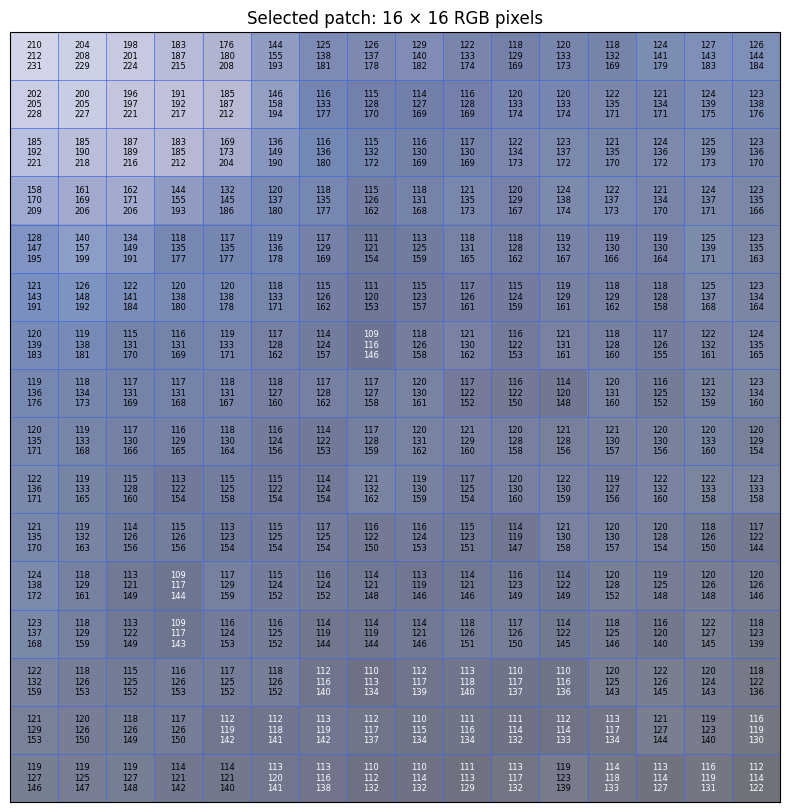

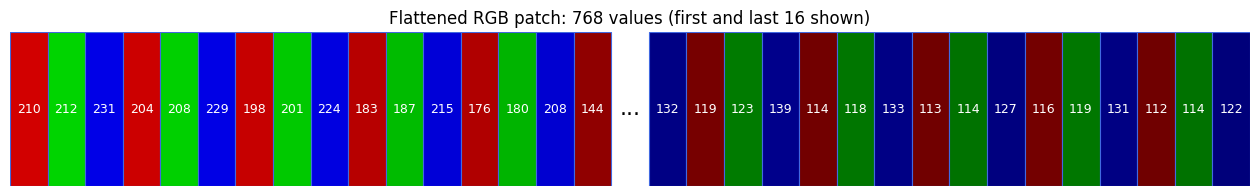

RGB patch: (16, 16, 3)
Flattened normalized patch: torch.Size([768])
Projection weights: torch.Size([768, 768])
Patch embeddings: torch.Size([1, 196, 768])
First 8 embedding values: [ 0.0817  0.0681  0.3495  0.595  -0.1066  0.1823  0.3796  0.1978]
Maximum absolute difference: 2.1457672119140625e-06
Matches convolution: True


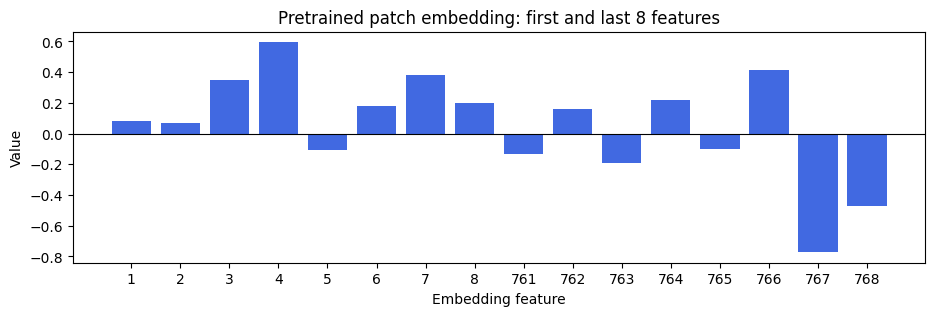

In [ ]:
rgb_patch = (processed[y0:y0 + patch_size, x0:x0 + patch_size] * 255).round().astype(np.uint8)
flat_rgb = rgb_patch.flatten()

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(rgb_patch, interpolation="nearest")

for row in range(patch_size):
    for col in range(patch_size):
        r, g, b = rgb_patch[row, col]
        color = "white" if rgb_patch[row, col].mean() < 125 else "black"
        ax.text(col, row, f"{r}\n{g}\n{b}", ha="center", va="center", fontsize=6, color=color)

ax.set_xticks(np.arange(-0.5, patch_size), minor=True)
ax.set_yticks(np.arange(-0.5, patch_size), minor=True)
ax.grid(which="minor", color="royalblue", linewidth=0.5)
ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
ax.set_title("Selected patch: 16 × 16 RGB pixels")
plt.show()

indices = list(range(16)) + [None] + list(range(flat_rgb.size - 16, flat_rgb.size))
fig, ax = plt.subplots(figsize=(16, 2))

for i, index in enumerate(indices):
    if index is None:
        ax.text(i + 0.5, 0.5, "...", ha="center", va="center", fontsize=16)
        continue

    value = int(flat_rgb[index])
    color = np.zeros(3)
    color[index % 3] = value / 255

    ax.add_patch(Rectangle((i, 0), 1, 1, facecolor=color, edgecolor="royalblue", linewidth=0.8))
    ax.text(i + 0.5, 0.5, str(value), ha="center", va="center", fontsize=9, color="white" if color.mean() < 0.4 else "black")

ax.set_xlim(0, len(indices))
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Flattened RGB patch: 768 values (first and last 16 shown)")
plt.show()

projection = model.vit.embeddings.patch_embeddings.projection

with torch.no_grad():
    patch_embeddings = projection(pixel_values).flatten(2).transpose(1, 2)
    flat = patch.flatten()
    weights = projection.weight.flatten(1)

    manual_embedding = flat @ weights.T + projection.bias
    embedding = patch_embeddings[0, patch_index]

    print("RGB patch:", rgb_patch.shape)
    print("Flattened normalized patch:", flat.shape)
    print("Projection weights:", weights.shape)
    print("Patch embeddings:", patch_embeddings.shape)
    print("First 8 embedding values:", embedding[:8].numpy().round(4))
    print("Maximum absolute difference:", (manual_embedding - embedding).abs().max().item())
    print("Matches convolution:", torch.allclose(manual_embedding, embedding, atol=1e-5))

    feature_indices = list(range(8)) + list(range(embedding.numel() - 8, embedding.numel()))
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.bar(range(16), embedding[feature_indices].numpy(), color="royalblue")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(16), [str(i + 1) for i in feature_indices])
    ax.set_xlabel("Embedding feature")
    ax.set_ylabel("Value")
    ax.set_title("Pretrained patch embedding: first and last 8 features")
    plt.show()

## 5. Add the CLS token and positional embeddings

The learnable **CLS token** is prepended to the 196 patch embeddings. A learned positional vector is added to each of the resulting 197 tokens:

$$Z=[\mathrm{CLS};E]+P$$

This corresponds to the patch-and-position embedding stage in Figure 1. We check the addition against the pretrained model's embedding layer.

In [28]:
with torch.no_grad():
    cls = model.vit.embeddings.cls_token.expand(1, -1, -1)
    positions = model.vit.embeddings.position_embeddings
    input_tokens = torch.cat([cls, patch_embeddings], dim=1) + positions
    reference_tokens = model.vit.embeddings(pixel_values)

    selected_token = patch_index + 1

    print("CLS token:", tuple(cls.shape))
    print("Positional embeddings:", tuple(positions.shape))
    print("Transformer input:", tuple(input_tokens.shape))
    print("Matches model:", torch.allclose(input_tokens, reference_tokens, atol=1e-5))

    print("\nSelected patch, first 8 features:")
    print("Patch:   ", patch_embeddings[0, patch_index, :8].numpy().round(4))
    print("Position:", positions[0, selected_token, :8].numpy().round(4))
    print("Sum:     ", input_tokens[0, selected_token, :8].numpy().round(4))


CLS token: (1, 1, 768)
Positional embeddings: (1, 197, 768)
Transformer input: (1, 197, 768)
Matches model: True

Selected patch, first 8 features:
Patch:    [ 0.0817  0.0681  0.3495  0.595  -0.1066  0.1823  0.3796  0.1978]
Position: [-0.0676  0.0025  0.0849  0.0165 -0.0505  0.6113 -0.056  -0.0744]
Sum:      [ 0.0142  0.0706  0.4344  0.6115 -0.1571  0.7936  0.3236  0.1234]


## 6. Queries, keys, and values

Inside the first encoder block, layer normalization is followed by three learned projections: **query (Q)**, **key (K)**, and **value (V)**. Each of the 12 attention heads works with 64 features per token.

Queries and keys determine attention weights; values are combined using those weights. We inspect the first eight values of the selected patch in head 1.

In [19]:
layer = model.vit.layers[0]
attn = layer.attention
with torch.no_grad():
    normalized = layer.layernorm_before(input_tokens)
    q = attn.q_proj(normalized).reshape(1, input_tokens.shape[1], num_heads, head_dim).transpose(1, 2)
    k = attn.k_proj(normalized).reshape(1, input_tokens.shape[1], num_heads, head_dim).transpose(1, 2)
    v = attn.v_proj(normalized).reshape(1, input_tokens.shape[1], num_heads, head_dim).transpose(1, 2)

print("Normalized tokens:", tuple(normalized.shape))
print("Q, K, V per head:", tuple(q.shape))
print("Selected patch, head 1 (first 8 values):")
print("Q:", q[0, 0, selected_token, :8].numpy().round(4))
print("K:", k[0, 0, selected_token, :8].numpy().round(4))
print("V:", v[0, 0, selected_token, :8].numpy().round(4))


Normalized tokens: (1, 197, 768)
Q, K, V per head: (1, 12, 197, 64)
Selected patch, head 1 (first 8 values):
Q: [ 0.8513 -0.8811 -0.8644  2.0991 -1.2605 -0.762  -1.0954  1.277 ]
K: [ 1.4225 -1.1479  1.1674  1.8008 -0.0162  1.454   0.8599 -0.8515]
V: [-0.2497  0.6627 -0.0528  0.2941  0.2436 -0.1412  0.1985 -0.3165]


## 7. Self-attention in the first encoder block

Each head compares queries with keys, applies softmax, and combines the values:

$$A=\operatorname{softmax}(QK^T/\sqrt{64}),\qquad O=AV$$

We reproduce the pretrained attention output and verify it against the model. On the image, **blue** marks the selected query patch and **orange** marks the six image patches receiving its highest attention weights in head 1. The CLS token is included in the calculation but has no image location.

Attention scores: (1, 12, 197, 197)
Attention weights: (1, 12, 197, 197)
Projected attention output: (1, 197, 768)
Matches model: True

Head 1, selected patch: 104
First 5 attention scores: [ 6.4972 -1.2996 -1.56   -1.5157 -1.699 ]
First 5 attention weights: [6.83307e-01 2.81000e-04 2.16000e-04 2.26000e-04 1.88000e-04]
CLS weight: 0.683307
Sum over all 197 tokens: 0.9999998211860657
Patch 104: 0.244386
Patch 118: 0.005422
Patch 117: 0.004511
Patch 75: 0.003990
Patch 80: 0.002529
Patch 105: 0.002077


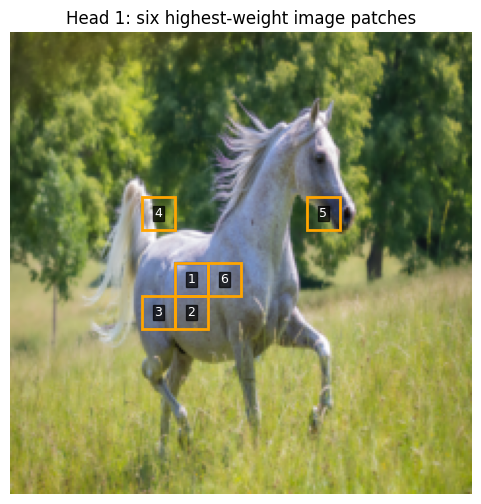

In [ ]:
with torch.no_grad():
    scores = q @ k.transpose(-2, -1) / head_dim**0.5
    attention = torch.softmax(scores, dim=-1)
    head_output = attention @ v
    combined = head_output.transpose(1, 2).reshape(1, input_tokens.shape[1], config.hidden_size)
    manual_output = attn.o_proj(combined)
    model_output = attn(normalized)[0]

print("Attention scores:", tuple(scores.shape))
print("Attention weights:", tuple(attention.shape))
print("Projected attention output:", tuple(manual_output.shape))
print("Matches model:", torch.allclose(manual_output, model_output, atol=1e-5))

selected_weights = attention[0, 0, selected_token]
strongest = torch.topk(selected_weights[1:], 6)
print("\nHead 1, selected patch:", patch_index + 1)
print("First 5 attention scores:", scores[0, 0, selected_token, :5].numpy().round(4))
print("First 5 attention weights:", selected_weights[:5].numpy().round(6))
print("CLS weight:", round(selected_weights[0].item(), 6))
print("Sum over all 197 tokens:", selected_weights.sum().item())
for index, weight in zip(strongest.indices, strongest.values):
    print(f"Patch {index.item() + 1}: {weight.item():.6f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(processed)
ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), patch_size, patch_size, fill=False, edgecolor="royalblue", linewidth=2.5))
for rank, index in enumerate(strongest.indices, 1):
    row, col = divmod(index.item(), cols)
    ax.add_patch(Rectangle((col * patch_size - 0.5, row * patch_size - 0.5), patch_size, patch_size, fill=False, edgecolor="orange", linewidth=2))
    ax.text(col * patch_size + patch_size / 2 - 0.5, row * patch_size + patch_size / 2 - 0.5, str(rank), ha="center", va="center", color="white", fontsize=9, bbox={"facecolor": "black", "alpha": 0.7, "pad": 1})
ax.set_title("Head 1: six highest-weight image patches")
ax.axis("off")
plt.show()


## 8. Compare the 12 attention heads

All heads process the same tokens with different learned projections. For the selected query patch, we list each head's highest-weight **image patch** and its attention weight for the CLS token. These are token-mixing weights, not measures of classification importance.

In [21]:
print("Head | Highest-weight image patch | Weight | CLS weight")
for h in range(num_heads):
    values = attention[0, h, selected_token]
    index = values[1:].argmax().item()
    print(f"{h + 1:4d} | {index + 1:26d} | {values[index + 1].item():.5f} | {values[0].item():.5f}")

Head | Highest-weight image patch | Weight | CLS weight
   1 |                        104 | 0.24439 | 0.68331
   2 |                        104 | 0.00643 | 0.93133
   3 |                        118 | 0.02098 | 0.84049
   4 |                        106 | 0.20890 | 0.01494
   5 |                        104 | 1.00000 | 0.00000
   6 |                        104 | 0.05365 | 0.83566
   7 |                        104 | 0.29386 | 0.62594
   8 |                        117 | 0.15343 | 0.00087
   9 |                        104 | 0.59594 | 0.34601
  10 |                         49 | 0.03886 | 0.00047
  11 |                        106 | 0.00095 | 0.99070
  12 |                         12 | 0.01725 | 0.40215


## 9. Follow tokens through the encoder

The right side of Figure 1 expands one encoder block: **normalization → multi-head attention → residual addition → normalization → MLP → residual addition**. ViT-Base/16 repeats this block 12 times. The MLP maps **768 → 3072 → 768**, and the token shape stays **197 × 768**.

We compare the selected patch and CLS token before and after the encoder. The final returned state includes the model's last normalization.

In [22]:
with torch.no_grad():
    vit_output = model.vit(pixel_values, output_hidden_states=True, output_attentions=True)
    states = vit_output.hidden_states

print("Hidden states:", len(states))
print("Shape of each:", tuple(states[0].shape))
print("\nSelected patch (first 8 features):")
print("Before:", states[0][0, selected_token, :8].numpy().round(4))
print("After: ", states[-1][0, selected_token, :8].numpy().round(4))
print("\nCLS token (first 8 features):")
print("Before:", states[0][0, 0, :8].numpy().round(4))
print("After: ", states[-1][0, 0, :8].numpy().round(4))
print("\nSelected patch and CLS token L2 norms:")
print("Block | Patch | CLS")
for i, state in enumerate(states):
    print(f"{i:5d} | {state[0, selected_token].norm().item():.3f} | {state[0, 0].norm().item():.3f}")

Hidden states: 13
Shape of each: (1, 197, 768)

Selected patch (first 8 features):
Before: [ 0.0142  0.0706  0.4344  0.6115 -0.1571  0.7936  0.3236  0.1234]
After:  [  6.4257  -3.7721  -9.9988  -1.2379  -2.2542   0.122    2.9459 -17.3117]

CLS token (first 8 features):
Before: [ 0.0195  0.0298 -0.5341 -0.001   0.8109  0.1082 -0.0441  0.0465]
After:  [-1.4945  0.7043 -2.8913  1.2728 -0.2491 -0.6715 -1.6801 -6.3694]

Selected patch and CLS token L2 norms:
Block | Patch | CLS
    0 | 12.510 | 5.181
    1 | 26.632 | 33.076
    2 | 31.817 | 37.895
    3 | 37.974 | 40.090
    4 | 40.797 | 41.977
    5 | 47.667 | 43.540
    6 | 57.591 | 48.551
    7 | 58.390 | 55.496
    8 | 60.601 | 65.313
    9 | 76.137 | 80.631
   10 | 89.522 | 95.424
   11 | 146.403 | 116.349
   12 | 201.439 | 122.303


## 10. Classify the image

As shown at the top left of Figure 1, the model takes the final **CLS representation** (768 features) and applies its pretrained classification head to produce **1,000 ImageNet logits**. Softmax converts these logits to probabilities. We display the five highest predictions.

Final CLS representation: (1, 768)
Classifier weights: (1000, 768)
Logits: (1, 1000)
sorrel: 82.29%
worm fence, snake fence, snake-rail fence, Virginia fence: 0.51%
horse cart, horse-cart: 0.29%
pedestal, plinth, footstall: 0.15%
cowboy hat, ten-gallon hat: 0.15%


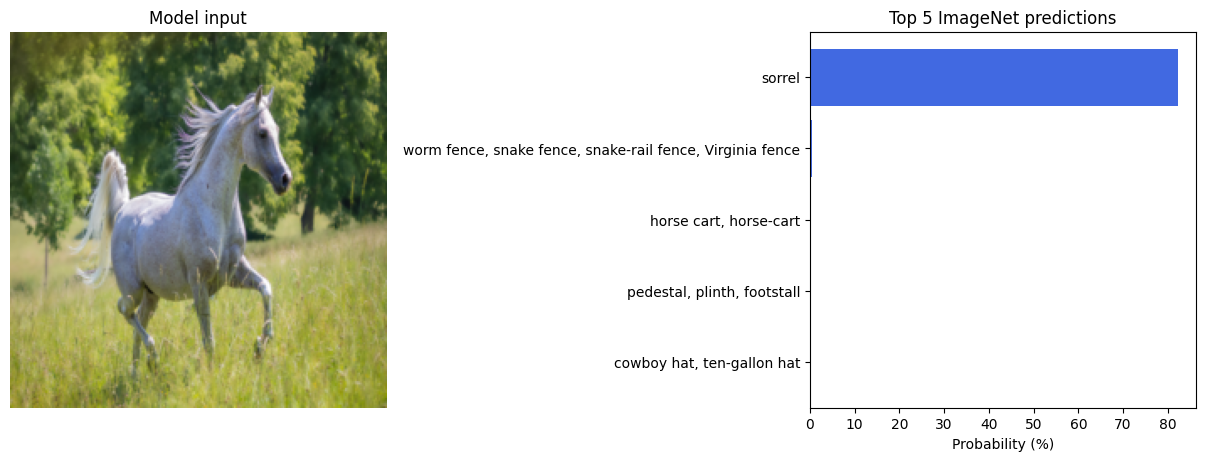

In [23]:
with torch.no_grad():
    cls_features = vit_output.last_hidden_state[:, 0]
    logits = model.classifier(cls_features)
    probabilities = torch.softmax(logits, dim=-1)[0]
    top_probs, top_ids = probabilities.topk(5)
    names = [config.id2label[i.item()] for i in top_ids]

print("Final CLS representation:", tuple(cls_features.shape))
print("Classifier weights:", tuple(model.classifier.weight.shape))
print("Logits:", tuple(logits.shape))
for name, prob in zip(names, top_probs):
    print(f"{name}: {prob.item():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].imshow(processed)
axes[0].axis("off")
axes[0].set_title("Model input")
axes[1].barh(names[::-1], top_probs.numpy()[::-1] * 100, color="royalblue")
axes[1].set_xlabel("Probability (%)")
axes[1].set_title("Top 5 ImageNet predictions")
plt.show()


## 11. Attention rollout (additional visualization)
**Attention rollout** averages heads within each block, adds an identity residual approximation, normalizes rows, and multiplies the resulting matrices across all 12 blocks.

We display the CLS-to-patch rollout as a 14 × 14 map, interpolated to image size for viewing. This is a summary of attention propagation, **not a causal explanation** of the prediction.

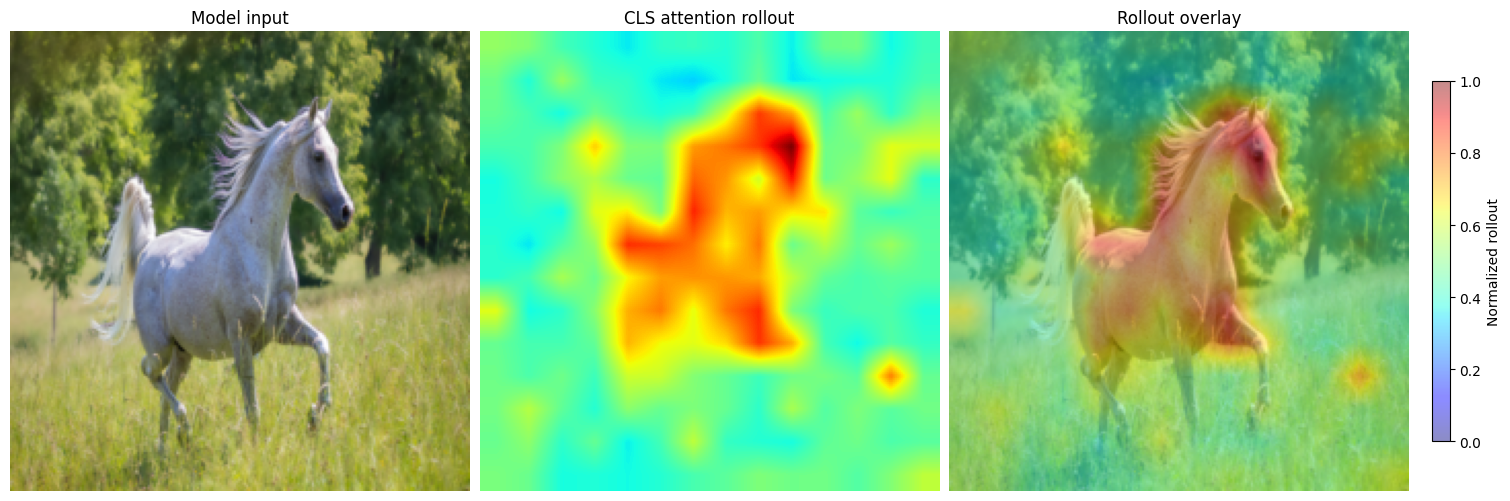

Layers: 12
Rollout matrix: (197, 197)
Spatial map: (14, 14)


In [ ]:
with torch.no_grad():
    attentions = vit_output.attentions
    rollout = torch.eye(input_tokens.shape[1], device=pixel_values.device)

    for layer_attention in attentions:
        average = layer_attention[0].mean(dim=0)
        average = average + torch.eye(average.shape[0], device=average.device)
        average = average / average.sum(dim=-1, keepdim=True)
        rollout = average @ rollout

    cls_attention = rollout[0, 1:].reshape(rows, cols)
    mask = torch.nn.functional.interpolate(cls_attention[None, None], size=processed.shape[:2], mode="bilinear", align_corners=False)[0, 0].cpu().numpy()

mask = mask / mask.max()

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
axes[0].imshow(processed)
axes[0].set_title("Model input")
axes[1].imshow(mask, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("CLS attention rollout")
axes[2].imshow(processed)
im = axes[2].imshow(mask, cmap="jet", alpha=0.45, vmin=0, vmax=1)
axes[2].set_title("Rollout overlay")
for ax in axes:
    ax.axis("off")
fig.colorbar(im, ax=axes[2], shrink=0.75, label="Normalized rollout")
plt.show()

print("Layers:", len(attentions))
print("Rollout matrix:", tuple(rollout.shape))
print("Spatial map:", tuple(cls_attention.shape))

## 12. Forward-pass summary

| Stage in Figure 1 | Tensor shape |
|---|---|
| Model input | 1 × 3 × 224 × 224 |
| Linear projection of 196 patches | 1 × 196 × 768 |
| CLS token and positional embeddings | 1 × 197 × 768 |
| 12 Transformer encoder blocks and final normalization | 1 × 197 × 768 |
| CLS representation | 1 × 768 |
| Classification head | 1 × 1000 |

The notebook verified the learned patch projection and the first block's attention calculation against the pretrained model.